# Bitcoin Market Intelligence: 14 years of minute data → product & risk decisions

**Scenario.** I'm a data analyst at a retail crypto-investing app (fictional). Leadership wants evidence for five decisions on the 2027 roadmap:

| # | Stakeholder question | Owner |
|---|---|---|
| Q1 | How do Bitcoin's market cycles behave, and where are we now? | Strategy |
| Q2 | How much risk are customers taking, and is it changing? | Risk & Compliance |
| Q3 | When does the market actually trade? (support staffing, maintenance, campaigns) | Operations / Growth |
| Q4 | Should we make **Recurring Buy (DCA)** the default way to invest? | Product |
| Q5 | Should we add a "cool-down" prompt when customers try to sell during a crash? | Product / CX |

**Data.** Kaggle *Bitcoin Historical Data*: 7.76M one-minute BTC/USD OHLCV bars (Bitstamp), 2012-01-01 → 2026-10-06.
The ETL (`src/pipeline.py`) cleans it into hourly and daily marts plus a SQLite DB. All metrics come from `src/analysis.py`, so the notebook, the SQL layer and the dashboard agree.

In [1]:
import sys, json
sys.path.insert(0, "../src")
import pandas as pd
import analysis as A
import charts as C

pd.set_option("display.float_format", "{:,.3f}".format)
daily, hourly = A.load_daily(), A.load_hourly()
close = daily["close"]
print(f"daily rows: {len(daily):,}   hourly rows: {len(hourly):,}   range: {daily.index.min():%Y-%m-%d} → {daily.index.max():%Y-%m-%d}")

daily rows: 5,393   hourly rows: 129,412   range: 2012-01-01 → 2026-10-06


## 0. Data quality

Before analysing anything: is the data trustworthy, and what are its quirks?

In [2]:
dq = json.loads((A.PROCESSED / "data_quality.json").read_text())
pd.Series({k: v for k, v in dq.items() if k != "trade_minute_share_by_year"}, name="value").to_frame()

,value
rows,7764703
start_utc,2012-01-01 00:01:00+00:00
end_utc,2026-10-06 03:43:00+00:00
null_values,0
duplicate_timestamps,0
missing_minutes,0
invalid_ohlc_rows,0
zero_volume_minute_share,0.169
one_minute_moves_over_20pct,10


In [3]:
pd.Series(dq["trade_minute_share_by_year"], name="share of minutes with ≥1 trade").to_frame().T

,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
share of minutes with ≥1 trade,0.051,0.608,0.758,0.709,0.668,0.920,0.962,0.967,0.985,0.993,0.973,0.961,0.967,0.989,0.996


**Findings**
- There are no nulls, duplicate timestamps, missing minutes or impossible OHLC rows. The file is complete minute by minute.
- **Caveat:** the source *forward-fills* minutes with no trades (price carried over, volume = 0). In 2012 only 5% of minutes had a trade, and until 2016 it was about two thirds. So:
  - daily-level analysis uses the full history;
  - intraday liquidity questions (Q3) use **2019+ only**, when 96%+ of minutes have trades;
  - cohort and holding-period analysis (Q4, Q5) starts in **2014**.
- Volume is from **one exchange (Bitstamp)**. It shows *relative* activity patterns, not total market volume.
- 10 one-minute moves above 20% happen in 2012–2013 (thin order book, the April 2013 flash crash). They are kept as real events because daily aggregation absorbs them.

## Q1. Market cycles: how does Bitcoin move, and where are we now?

In [4]:
A.yearly_summary(daily)

,open,close,high,low,return,ann_volatility,max_drawdown,usd_volume_bn,days_up_pct,partial_year
year,,,,,,,,,,
2012,4.580,13.240,16.410,3.800,1.891,0.854,-0.408,0.006,0.538,False
2013,13.240,732.000,"1,163.000",12.770,54.287,1.498,-0.710,1.552,0.616,False
2014,732.000,321.000,995.000,275.000,-0.561,0.756,-0.662,2.616,0.452,False
2015,321.000,430.890,502.000,152.400,0.342,0.711,-0.457,1.546,0.515,False
2016,430.890,966.300,980.740,352.000,1.243,0.483,-0.296,1.113,0.574,False
2017,966.300,"13,880.000","19,666.000",751.340,13.364,0.929,-0.351,21.778,0.595,False
2018,"13,880.000","3,693.300","17,234.990","3,122.280",-0.734,0.846,-0.815,30.748,0.490,False
2019,"3,693.850","7,168.360","13,880.000","3,322.190",0.941,0.701,-0.488,23.159,0.515,False
2020,"7,160.690","28,992.790","29,300.000","3,850.000",3.049,0.810,-0.533,33.291,0.579,False


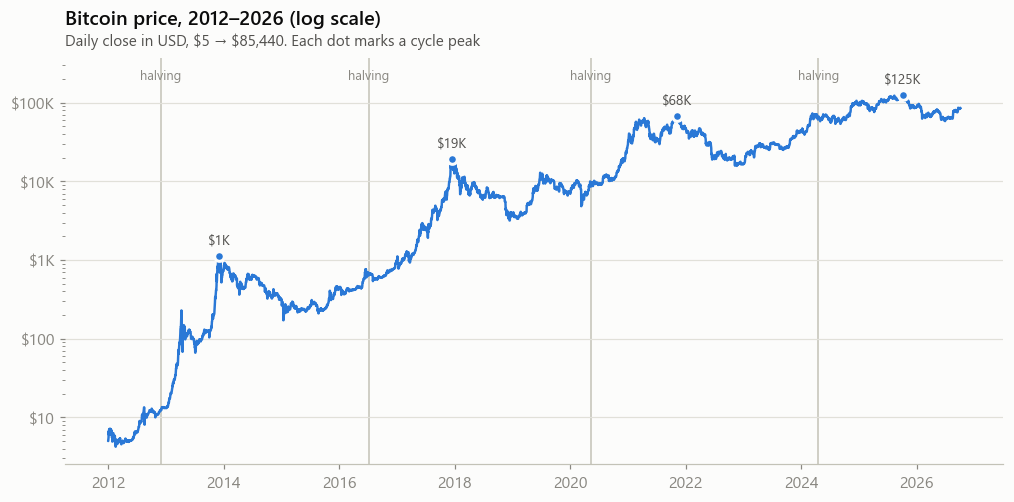

In [5]:
C.price_history(daily);

In [6]:
A.halving_cycles(close)

,halving,price_at_halving,cycle_peak_date,cycle_peak,days_halving_to_peak,halving_to_peak_multiple,post_peak_low_date,post_peak_low,post_peak_drawdown,cycle_complete
0,2012-11-28,12.220,2013-12-04,"1,132.010",371,92.636,2015-01-14,171.410,-0.849,True
1,2016-07-09,647.780,2017-12-16,"19,187.780",525,29.621,2018-12-15,"3,179.540",-0.834,True
2,2020-05-11,"8,571.980",2021-11-08,"67,559.000",546,7.881,2022-11-21,"15,766.000",-0.767,True
3,2024-04-20,"64,990.000",2025-10-06,"124,728.000",534,1.919,2026-06-30,"58,526.170",-0.531,False


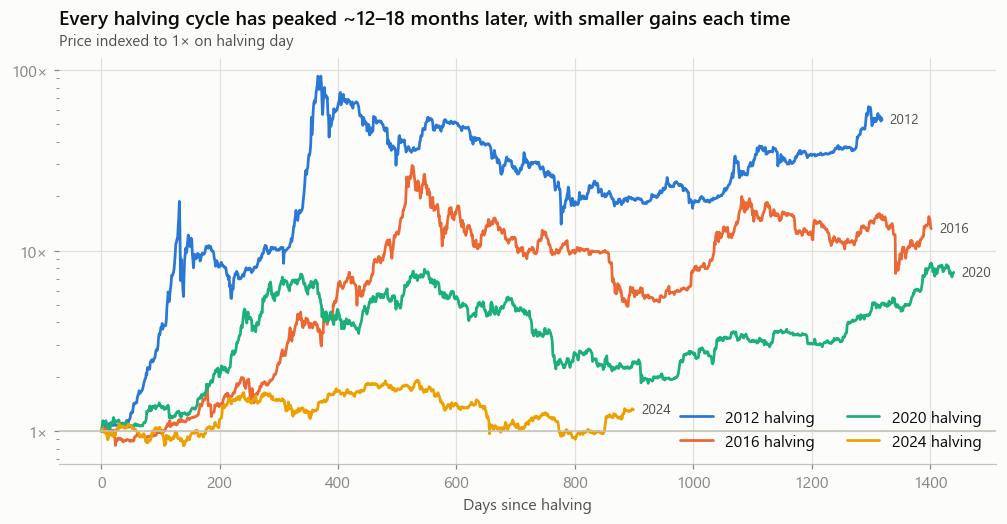

In [7]:
C.halving_cycles_indexed(daily);

In [8]:
A.drawdown_episodes(close)

,peak_date,peak_price,trough_date,trough_price,depth,days_peak_to_trough,recovery_date,days_underwater,recovered
0,2013-04-09,229.000,2013-07-06,66.340,-0.710,88,2013-11-05,210,True
1,2013-12-04,"1,132.010",2015-01-14,171.410,-0.849,406,2017-02-23,1177,True
2,2017-12-16,"19,187.780",2018-12-15,"3,179.540",-0.834,364,2020-11-30,1080,True
3,2021-04-13,"63,564.480",2021-07-20,"29,786.580",-0.531,98,2021-10-19,189,True
4,2021-11-08,"67,559.000",2022-11-21,"15,766.000",-0.767,378,2024-03-04,847,True
5,2025-10-06,"124,728.000",2026-06-30,"58,526.170",-0.531,267,None,365,False


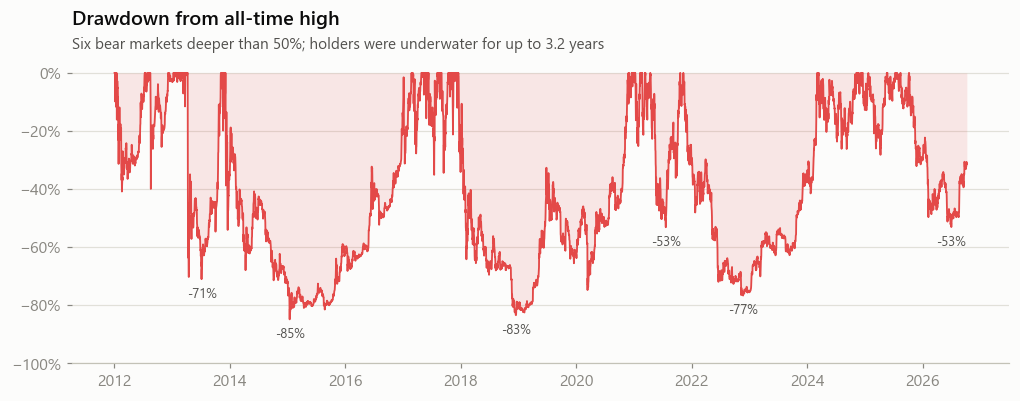

In [9]:
C.underwater(daily);

**Findings**
- Price went from **$5 to ~$85K**. Each halving cycle peaked **371–546 days after the halving**, a consistent 12–18-month window.
- **The gains shrink every cycle:** 93× → 30× → 7.9× → 1.9× from halving to peak. The asset is maturing, so "the next cycle will look like the last one" is a weak assumption.
- **Bear markets are deep but getting shallower:** −85%, −83%, −77%, and −53% so far for the current cycle. Holders were underwater for up to **1,177 days (3.2 years)**.
- **Where we are now:** about 31% below the October 2025 all-time high, after a −53% low in June 2026. That's a drawdown regime, not a bull market.

## Q2. Risk: how much risk do customers take, and is it changing?

In [10]:
A.risk_by_era(daily)

,days,ann_volatility,VaR_95,CVaR_95,VaR_99,days_abs_move_gt_5pct,days_abs_move_gt_10pct,worst_day,best_day
era,,,,,,,,,
2012-2016 early market,1826,0.909,-0.057,-0.111,-0.154,0.147,0.048,-0.485,0.401
2017-2020 retail boom,1461,0.819,-0.065,-0.096,-0.110,0.179,0.040,-0.390,0.269
2021-2023 institutional,1095,0.650,-0.057,-0.079,-0.099,0.122,0.019,-0.156,0.195
2024-2026 ETF era,1010,0.475,-0.037,-0.053,-0.062,0.054,0.004,-0.140,0.123


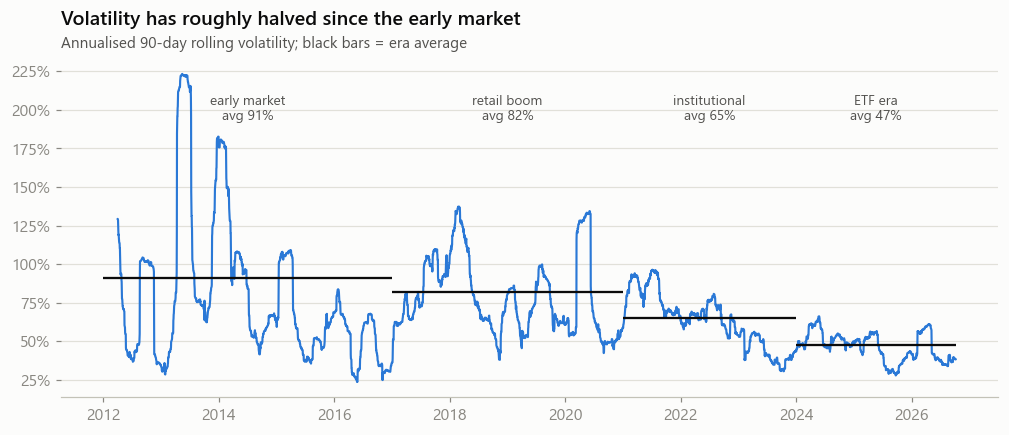

In [11]:
C.volatility(daily);

**Findings**
- Annualised volatility fell from **91% (2012–16) to 47% (2024–26)**. That's still ~3× the S&P 500, but a structural decline.
- **Tail risk collapsed:** days with a ±10% move went from 4.8% of days to **0.4%**. The 1-in-20-day loss (VaR 95) went from −5.7% to **−3.7%**.
- The worst single day in the ETF era is −14%, versus −49% in the early market.
- **Implication:** risk disclosures, margin/collateral haircuts and "expected move" UI copy calibrated on pre-2021 data overstate today's risk by about 2×. Recalibrate on a rolling window, not all history.

## Q3. When does the market trade? (2019–2026)

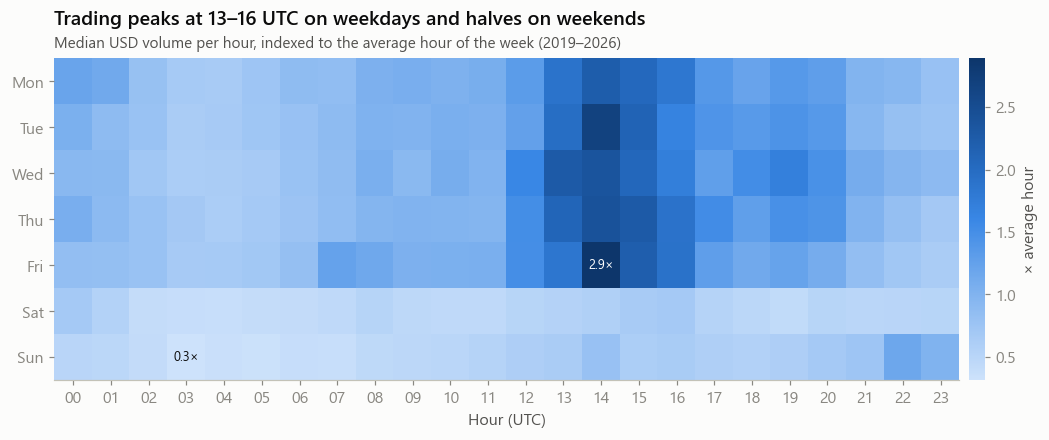

In [12]:
C.liquidity_heatmap(hourly);

In [13]:
A.weekday_profile(hourly)

,median_volume_usd,mean_abs_return,volume_vs_weekday_avg
weekday,,,
Monday,"97,607,837.296",0.026,0.968
Tuesday,"102,016,941.032",0.022,1.011
Wednesday,"106,593,225.946",0.025,1.057
Thursday,"102,675,533.256",0.024,1.018
Friday,"95,486,060.007",0.023,0.947
Saturday,"42,185,572.860",0.012,0.418
Sunday,"49,967,250.229",0.018,0.495


In [14]:
A.intraday_heatmaps(hourly)['abs_return_bps'].round(0)

hour_utc,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
weekday,,,,,,,,,,,,,,,,,,,,,
Monday,59.000,47.000,40.000,36.000,30.000,33.000,43.000,40.000,38.000,40.000,...,65.000,60.000,47.000,47.000,43.000,46.000,45.000,42.000,41.000,44.000
Tuesday,47.000,45.000,38.000,35.000,36.000,33.000,35.000,33.000,44.000,38.000,...,70.000,55.000,52.000,45.000,48.000,42.000,44.000,40.000,39.000,36.000
Wednesday,47.000,38.000,36.000,39.000,32.000,33.000,33.000,41.000,40.000,34.000,...,56.000,54.000,49.000,43.000,51.000,50.000,52.000,43.000,42.000,42.000
Thursday,44.000,44.000,37.000,37.000,33.000,32.000,33.000,36.000,39.000,37.000,...,62.000,60.000,55.000,51.000,43.000,44.000,46.000,41.000,38.000,39.000
Friday,45.000,50.000,48.000,35.000,37.000,36.000,36.000,42.000,46.000,42.000,...,65.000,62.000,48.000,41.000,40.000,38.000,42.000,40.000,33.000,33.000
Saturday,40.000,32.000,27.000,22.000,26.000,26.000,25.000,26.000,29.000,26.000,...,29.000,30.000,30.000,32.000,25.000,25.000,32.000,32.000,29.000,30.000
Sunday,34.000,30.000,29.000,27.000,28.000,26.000,24.000,24.000,29.000,29.000,...,34.000,31.000,36.000,34.000,30.000,35.000,39.000,41.000,53.000,45.000


**Findings**
- Activity peaks **Mon–Fri 13:00–16:00 UTC** (US market open overlapping the European afternoon). Friday 14:00 runs at **2.9× the average hour**.
- The quietest slot is **Sat/Sun 02:00–06:00 UTC** at about **0.3–0.4×**. Weekend volume is **~45% of a weekday**.
- Price movement follows the same shape: average absolute hourly moves are largest at 14:00 UTC. So the busiest hour is also the most volatile hour.
- **Implication:** schedule maintenance and deploys for **Saturday ~03:00 UTC**. Put the most customer-support staff on 13:00–17:00 UTC on weekdays. Avoid releasing app updates into the 14:00 UTC peak.

## Q4. Should Recurring Buy (DCA) be the default way to invest?

First, the baseline question customers really ask: *if I buy on a random day, how likely am I to be in profit?*

In [15]:
A.holding_period_odds(close)

,days,buy_days_tested,prob_profit,prob_loss_gt_50pct,p10_return,median_return,p90_return
horizon,,,,,,,
1 day,1,4661,0.516,0.000,-0.034,0.001,0.040
1 week,7,4655,0.532,0.000,-0.093,0.005,0.124
1 month,30,4632,0.552,0.001,-0.189,0.023,0.335
3 months,91,4571,0.565,0.011,-0.312,0.065,0.814
6 months,182,4480,0.611,0.049,-0.414,0.226,1.733
1 year,365,4297,0.676,0.113,-0.528,0.615,3.573
2 years,730,3932,0.803,0.033,-0.302,1.900,10.816
3 years,1095,3567,0.997,0.000,0.707,3.132,19.348
4 years,1461,3201,1.000,0.000,1.261,5.488,26.388


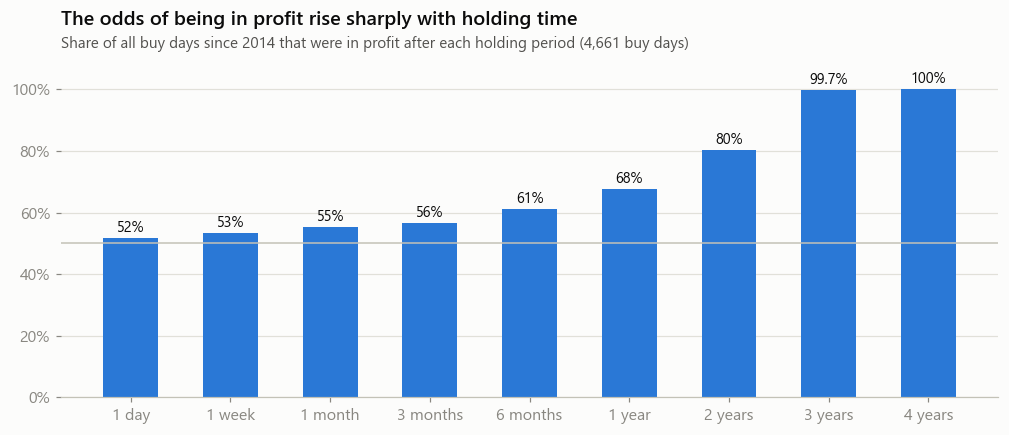

In [16]:
C.holding_odds(daily);

Next, a weekly $100 recurring buy vs. investing the same total on day 1, for every monthly start cohort since 2014:

In [17]:
A.dca_summary(close)

,cohorts,dca_prob_profit,lump_prob_profit,dca_median_roi,lump_median_roi,dca_worst_roi,lump_worst_roi,dca_roi_iqr,lump_roi_iqr,share_dca_beats_lump
horizon_months,,,,,,,,,,
12,142,0.718,0.676,0.324,0.632,-0.515,-0.721,0.747,1.780,0.359
24,130,0.815,0.785,0.830,1.955,-0.481,-0.543,1.668,4.088,0.292
36,118,0.958,1.000,1.623,3.027,-0.100,0.007,3.054,7.530,0.254
48,106,1.000,1.000,2.209,5.717,0.343,0.450,4.048,13.833,0.198


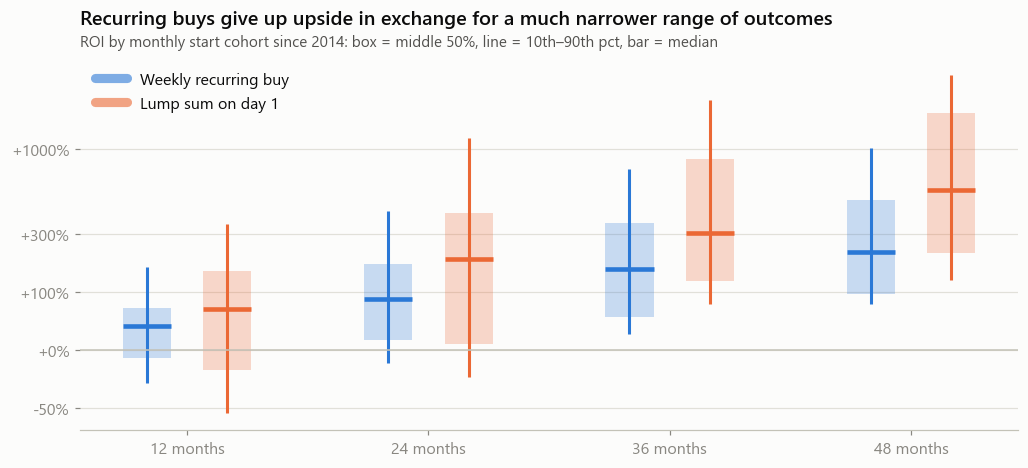

In [18]:
C.dca_vs_lump(daily);

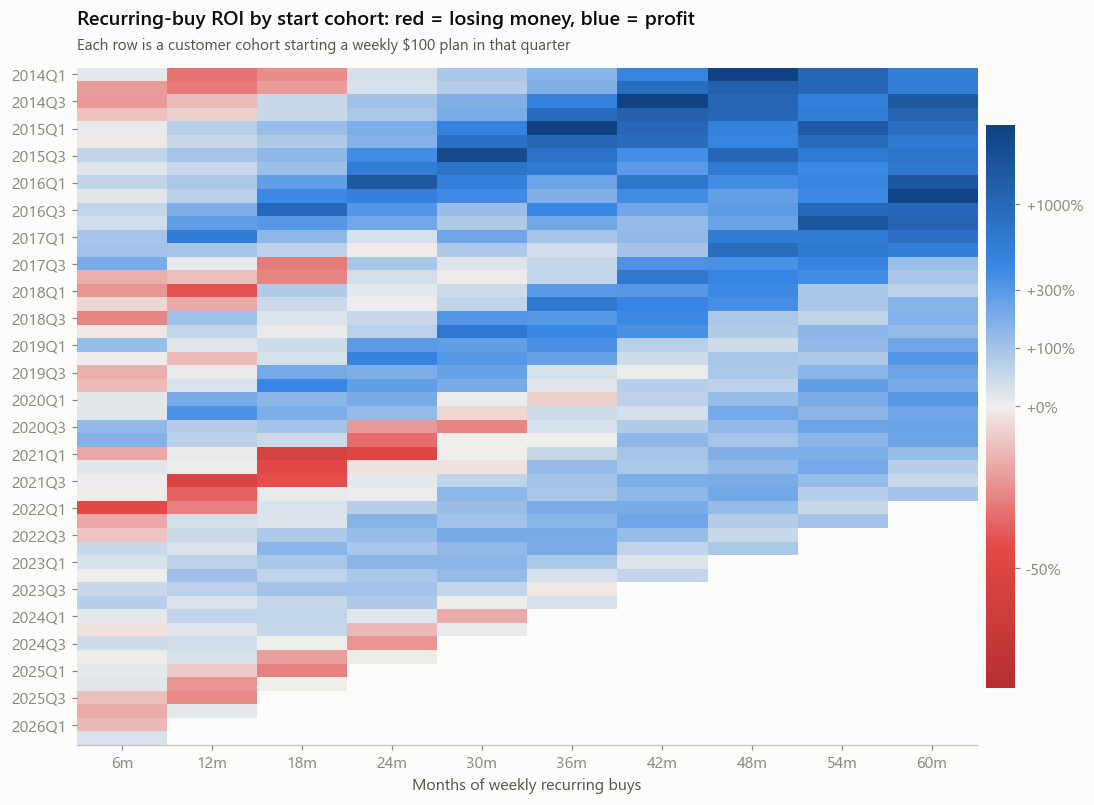

In [19]:
C.dca_cohort_heatmap(daily);

Does the *day of the week* the recurring buy runs on matter? (A feature request we keep getting.)

In [20]:
A.dca_weekday_effect(close)

,buys,avg_cost,vs_best_day
weekday,,,
Monday,458,"16,190.956",0.005
Tuesday,458,"16,203.360",0.006
Wednesday,457,"16,208.865",0.006
Thursday,457,"16,112.754",0.000
Friday,457,"16,166.286",0.003
Saturday,457,"16,193.581",0.005
Sunday,457,"16,171.972",0.004


**Findings**
- Holding time drives outcomes. A 1-day hold was profitable 52% of the time (a coin flip). After 1 year it was 68%, after 2 years 80%, and after 3+ years **99.7–100%** for every buy day since 2014.
- **Lump sum has the higher median return** and beats weekly DCA in 64–80% of cohorts, because the long-run trend was up.
- **But DCA dramatically narrows the range of outcomes.** The worst 12-month result improves from −72% to −51%. The spread between good and bad cohorts (IQR) shrinks by **~60–70%**. The cohorts that lost money with DCA (red in the heatmap) started just before a bear market (late 2017, 2020–21, 2024–25). **96% of cohorts were in profit by month 36, and every cohort by month 42.** Part 2 (`advanced_analysis.ipynb`) stress-tests this with a Monte Carlo: these windows overlap heavily and come from one growth era.
- **The day of the week doesn't matter.** The best and worst weekday differ by **0.6%** in average cost. Building a "smart day picker" isn't worth the engineering time.
- **Implication:** make weekly Recurring Buy the default onboarding path, and position it as *"a smoother ride"*, not *"higher returns"* (the data doesn't support that claim). A narrower outcome range means fewer customers churning after a bad first year.

## Q5. Should we add a cool-down prompt before panic selling?

In [21]:
events, crash = A.crash_event_study(daily)
crash

,events,after_crash_median,after_crash_prob_up,baseline_median,baseline_prob_up
horizon_days,,,,,
1,37,0.029,0.676,0.001,0.516
7,37,0.018,0.541,0.005,0.532
30,37,0.051,0.622,0.023,0.552
90,37,0.072,0.514,0.062,0.565
365,36,0.170,0.528,0.615,0.676


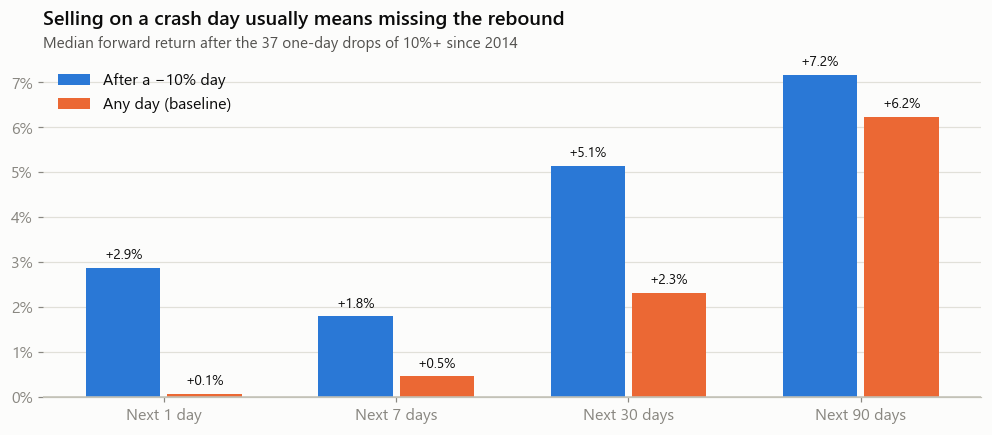

In [22]:
C.crash_rebound(daily);

In [23]:
events.sort_values('drop').head(10)

,drop,close,fwd_1d,fwd_7d,fwd_30d,fwd_90d,fwd_365d
datetime,,,,,,,
2020-03-12 00:00:00+00:00,-0.390,"4,841.670",0.161,0.277,0.422,1.044,10.829
2014-03-27 00:00:00+00:00,-0.183,475.000,0.057,-0.050,-0.034,0.180,-0.478
2014-04-10 00:00:00+00:00,-0.178,363.120,0.165,0.377,0.254,0.713,-0.350
2017-09-14 00:00:00+00:00,-0.165,"3,227.790",0.146,0.121,0.797,4.034,1.006
2016-01-15 00:00:00+00:00,-0.162,360.000,0.075,0.063,0.125,0.180,1.273
2022-06-13 00:00:00+00:00,-0.156,"22,450.430",-0.016,-0.084,-0.099,-0.027,0.155
2015-01-13 00:00:00+00:00,-0.151,227.000,-0.245,-0.072,-0.018,-0.017,0.906
2014-01-07 00:00:00+00:00,-0.146,785.000,0.049,0.039,-0.027,-0.430,-0.647
2022-11-09 00:00:00+00:00,-0.144,"15,877.000",0.105,0.049,0.079,0.465,1.311


**Robustness check.** Is −10% the right trigger? How often does it fire today, and does a looser −5% trigger show the same rebound?

In [24]:
r = daily.loc["2024":, "pct_return"]
print(f"Since 2024: {(r <= -0.10).sum()} day(s) at -10% or worse, {(r <= -0.05).sum()} days at -5% or worse (of {r.count()})")
_, crash5 = A.crash_event_study(daily, threshold=-0.05)
crash5

Since 2024: 1 day(s) at -10% or worse, 24 days at -5% or worse (of 1010)


,events,after_crash_median,after_crash_prob_up,baseline_median,baseline_prob_up
horizon_days,,,,,
1,127,0.002,0.528,0.001,0.516
7,127,-0.008,0.465,0.005,0.532
30,127,-0.005,0.465,0.023,0.552
90,127,0.020,0.528,0.062,0.565
365,123,0.343,0.602,0.615,0.676


**Findings**
- After the **37 one-day drops of 10%+** since 2014, the next day was up **68%** of the time (baseline 52%), with a median gain of **+2.9%**. The 30-day median was **+5.1%**, versus +2.3% on a normal day.
- A customer who sells at the close of a crash day typically **sells near a short-term low** and misses the rebound.
- **Caveat:** crash days cluster in bear markets, so the 1-year outcome after a crash is *worse* than baseline (+17% vs +62%). The rebound effect is short-term. This argues for a *pause*, not for "buy the dip" advice, which we must not give.
- **The robustness check changes the answer.** A −10% day has happened only **once since 2024**. At a looser −5% trigger (127 events) the rebound **disappears**: the next 30 days were up only 47% of the time, against 55% baseline. The effect is real only for extreme crashes, and those have nearly vanished as volatility fell.
- **Implication:** **deprioritise** the cool-down feature. It would almost never trigger in today's market, and a lower trigger has no evidence behind it. Keep it on the backlog with a re-evaluation trigger: revisit if 90-day volatility goes back above 80%. Lighter crash-day education (a holding-period reminder) is a cheaper alternative.

## Recommendations

| # | Recommendation | Evidence | Success metric |
|---|---|---|---|
| 1 | Make **weekly Recurring Buy** the default onboarding path; market it as risk reduction | Worst 12-month outcome −51% vs −72%; outcome spread −60%+ | % new users on a recurring plan; 12-month retention |
| 2 | **Don't build** a "best day to buy" optimiser | Weekday cost difference ≤ 0.6% | Engineering time saved |
| 3 | Show customers a **simulated range of outcomes** for their plan (see part 2: the historical 99.7% overstates safety) | Holding-period table + part-2 Monte Carlo | Fewer sells in the first 90 days |
| 4 | **Deprioritise** the crash-day cool-down; revisit if volatility returns | Rebound exists after −10% days (n=37) but they happened once since 2024; none at −5% (n=127) | Re-evaluate if 90-day vol > 80% |
| 5 | **Maintenance window: Sat 03:00 UTC.** Support peak staffing Mon–Fri 13–17 UTC | 0.3× vs 2.9× average hourly volume | Incidents during peak, support SLA |
| 6 | **Recalibrate risk limits** on a rolling 2-year window | Volatility 91% → 47%; ±10% days 4.8% → 0.4% | Collateral efficiency vs loss events |

\* Past performance does not guarantee future results. Any in-app copy needs compliance review.

## Limitations
- One exchange's volume is used as a proxy for market activity.
- 14 years of a single, trending asset means few independent cycles: four halvings is a tiny sample. The cycle findings are descriptive, not predictive.
- Backtests ignore fees and spreads. These would slightly favour fewer, larger buys (lump sum or monthly).
- Survivorship: we analyse Bitcoin *because* it survived. Conclusions don't transfer to other coins.